# Memory Locality in a 2D Finite-Difference Stencil
This notebook isolates one systems-level question: **can two mathematically identical stencil kernels have very different runtimes because they traverse memory differently?**
Both kernels perform the same floating-point work and produce the same numerical result. The only intentional difference is loop ordering. Because standard NumPy arrays are stored in C order, iterating over the last index in the inner loop accesses contiguous memory, while reversing the loops creates strided access.

In [1]:
!pip install numba

## Experimental setup
The kernels are JIT-compiled with Numba so the comparison reflects compiled loop behavior rather than Python interpreter overhead. Timing results are hardware- and environment-dependent, so the measured ratios should be interpreted as observations from this run rather than universal constants.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from numba import njit

# NumPy arrays are C-contiguous by default: the last index varies contiguously in memory.
N = 2048
u = np.random.rand(N, N)
out1 = np.zeros_like(u)
out2 = np.zeros_like(u)
r = 0.2

## 1. Two equivalent stencil kernels
stencil_row_major traverses the last array dimension in the inner loop. stencil_col_major performs the same update but traverses the first dimension in the inner loop. The arithmetic per grid point is unchanged.

In [2]:
@njit
def stencil_row_major(u, out, r):
    N = u.shape[0]
    """Apply the 5-point update with contiguous access in the inner loop."""
    for i in range(1, N - 1):
        for j in range(1, N - 1):
            # j is the contiguous (last) dimension for a C-order NumPy array.
            out[i, j] = (
                u[i, j]
                + r * (
                    u[i + 1, j]
                    + u[i - 1, j]
                    + u[i, j + 1]
                    + u[i, j - 1]
                    - 4.0 * u[i, j]
                )
            )

In [3]:
@njit
def stencil_col_major(u, out, r):
    N = u.shape[0]
    """Apply the same arithmetic with strided access in the inner loop."""
    for j in range(1, N - 1):
        for i in range(1, N - 1):
            # i varies in the inner loop, so accesses are strided for a C-order array.
            out[i, j] = (
                u[i, j]
                + r * (
                    u[i + 1, j]
                    + u[i - 1, j]
                    + u[i, j + 1]
                    + u[i, j - 1]
                    - 4.0 * u[i, j]
                )
            )

## 2. Correctness check
Before comparing performance, both compiled kernels are evaluated on the same input and checked with np.allclose. This prevents a faster but mathematically different implementation from being treated as a valid optimization.

In [7]:
stencil_row_major(u, out1, r)
stencil_col_major(u, out2, r)
print(np.allclose(out1, out2))

True


## 3. Runtime benchmark at $2048^2$
The kernels are already compiled by the correctness check above, so Numba compilation time is excluded. The benchmark reports the median of repeated runs.

In [4]:
# Use the median of repeated wall-clock measurements to reduce sensitivity to noise.
def benchmark(func, u, out, r, repeats=5):
    times = []

    for _ in range(repeats):
        start = time.perf_counter()
        func(u, out, r)
        end = time.perf_counter()

        times.append(end - start)

    return np.median(times)

t_row = benchmark(
    stencil_row_major,
    u,
    out1,
    r
)
t_col = benchmark(
    stencil_col_major,
    u,
    out2,
    r
)
print("Row-major friendly:", t_row, "seconds")
print("Column-like access :", t_col, "seconds")
print("Speed ratio:", t_col / t_row)

Row-major friendly: 0.0034952498972415924 seconds
Column-like access : 0.04744391585700214 seconds
Speed ratio: 13.573826550840982


## 4. Scaling with grid size
The same experiment is repeated from $256^2$ through $4096^2$. As the working set outgrows the faster cache levels, the effect of memory-access pattern becomes increasingly visible.

In [5]:
sizes = [256, 512, 1024, 2048, 4096]

row_times = []
col_times = []

for N in sizes:
    u = np.random.rand(N, N)
    out1 = np.zeros_like(u)
    out2 = np.zeros_like(u)
    stencil_row_major(u, out1, r)
    stencil_col_major(u, out2, r)
    t_row = benchmark(
        stencil_row_major,
        u,
        out1,
        r,
        repeats=3
    )
    t_col = benchmark(
        stencil_col_major,
        u,
        out2,
        r,
        repeats=3
    )
    row_times.append(t_row)
    col_times.append(t_col)

    print(
        N,
        "row =", t_row,
        "column =", t_col
    )

256 row = 0.00010483316145837307 column = 0.0003546669613569975
512 row = 0.00014333310537040234 column = 0.0032252499368041754
1024 row = 0.0006143748760223389 column = 0.008449290879070759
2048 row = 0.0024425422307103872 column = 0.04398283385671675
4096 row = 0.012457167031243443 column = 0.24744724994525313


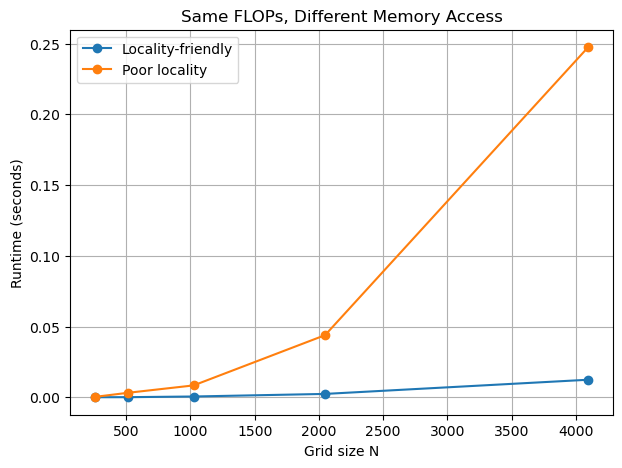

In [6]:
plt.figure(figsize=(7, 5))
plt.plot(sizes,row_times,marker="o",label="Locality-friendly")
plt.plot(sizes,col_times,marker="o",label="Poor locality")
plt.xlabel("Grid size N")
plt.ylabel("Runtime (seconds)")
plt.title("Same FLOPs, Different Memory Access")
plt.legend()
plt.grid()
plt.show()

## Interpretation
The two kernels have essentially the same arithmetic complexity, yet the locality-friendly ordering is much faster in the recorded runs. The experiment illustrates an important scientific-computing lesson: operation count alone does not determine runtime. Memory layout, cache behavior, and data movement can dominate stencil performance.

## Limitation
- This is a single-node CPU microbenchmark, not a distributed-memory scaling study.
- No hardware performance counters are collected, so cache misses and memory bandwidth are inferred from the access pattern rather than directly measured.
- Exact timing ratios vary across processors, compilers, background load, and memory systems.